In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
# Permite importar tu paquete de src/ sin instalarlo
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))

# 02 · EDA — qué hay realmente en mis datos

**Proyecto RiskVision · Grupo 6.** Dataset: *Default of Credit Card Clients* (UCI, licencia CC BY 4.0), 30.000 clientes de un banco de Taiwán.

## Para qué sirve este notebook
El análisis exploratorio (EDA) describe los datos y propone qué arreglar, qué conservar y qué vigilar. Termina en una **tabla de decisiones**, cada una con una cifra y un motivo, que pasa a `reports/01_eda.md` y se convierte en código en las etapas siguientes.

## Cómo leerlo
Cada sección tiene tres partes: **la pregunta** (qué queremos saber), **la celda de código** (cómo se mide) y **la lectura** (qué significa el resultado). Si solo tiene unos minutos, lea los textos y la tabla final.

## Palabras clave
| Término | Significado simple |
|---|---|
| **Variable objetivo** | Lo que queremos predecir: si el cliente no paga el mes siguiente (`1`) o paga (`0`) |
| **Línea base** | Resultado de una regla muy simple. Un modelo solo vale la pena si la supera |
| **Fuga de información** | Cuando el modelo «ve» datos que en la vida real no tendría al decidir, y por eso parece mejor de lo que es |
| **Estratificar** | Dividir los datos manteniendo la misma proporción de la clase rara en cada parte |
| **ROC AUC** | Qué tan bien el modelo ordena a los clientes del menos al más riesgoso (0,5 = azar, 1,0 = perfecto) |

**Preguntas guía:** (1) unidad de análisis · (2) objetivo · (3) suciedad · (4) qué debería ser estable · (5) sospecha de fuga.
Resultados de referencia del notebook de selección de modelo: `model_selection_classification_REVISION_FINAL.ipynb`.

**Qué datos usa cada sección.** Las secciones 1 a 7 usan el dataset completo (30.000 clientes), incluidas las filas de la prueba original. Solo describen y comparan: no prueban causas ni sirven como evaluación independiente. La sección 8 sí calcula sus métricas únicamente con el 80 % de entrenamiento. Además, la prueba original ya se evaluó en el notebook de selección, por eso no es una evaluación final independiente.

**Cómo se decidirá de aquí en adelante.** Las variables, el preprocesamiento, el modelo, los hiperparámetros, la calibración y el umbral se deciden solo con validación dentro del entrenamiento. Se propone una validación cruzada anidada. La prueba se reportará al final como evaluación complementaria; una evaluación realmente independiente necesitaría datos nuevos.

*Las salidas de las celdas son las de la ejecución anterior; la revisión H1 y esta edición solo cambiaron los textos.*


## 0. Cargar los datos
**Qué hace la celda:** busca el archivo en `data/raw/` y lo carga. El archivo de UCI trae una primera fila auxiliar (`X1…X23`), por eso se leen los nombres reales desde la segunda fila. Define también dos nombres que usaremos todo el notebook: `ID_COL` (quién es el cliente) y `TARGET` (lo que predecimos).

In [2]:
import pandas as pd

RAW_DIR = Path.cwd().resolve().parent / "data" / "raw"
files = sorted(p for p in RAW_DIR.glob("*") if p.suffix.lower() in {".csv", ".parquet", ".xlsx", ".xls"})

if not files:
    df = None
    print("Todavía no hay datos. Coloca tu dataset en data/raw/ (csv, parquet, xlsx o xls) y vuelve a ejecutar.")
else:
    path = files[0]
    if path.suffix == ".parquet":
        df = pd.read_parquet(path)
    elif path.suffix in {".xlsx", ".xls"}:
        # El archivo de UCI trae una primera fila auxiliar (X1...X23/Y); los nombres reales están en la segunda.
        df = pd.read_excel(path, header=1)
    else:
        df = pd.read_csv(path, low_memory=False)
    print(f"{path.name}: {df.shape[0]:,} filas x {df.shape[1]} columnas")
    # No hay nombres, documentos ni teléfonos: solo un ID anónimo (se excluye del modelo, no se borra aquí).

ID_COL = "ID"                            # identifica al cliente
TARGET = "default payment next month"    # 1 = incumple el próximo mes, 0 = paga

default of credit card clients.xls: 30,000 filas x 25 columnas


## 1. ¿Cuál es la unidad de análisis? ¿Qué representa una fila?
**Pregunta:** ¿una fila es un cliente, una transacción, un cliente en un mes? ¿Algún cliente aparece en **varias filas**?
**Por qué importa:** si un mismo cliente estuviera en varias filas, habría que dividir los datos *por cliente*; de lo contrario el modelo vería al mismo cliente al entrenar y al probar, y parecería mejor de lo que es.
**Qué hace la celda:** cuenta cuántos clientes distintos hay y cuántas filas tiene cada uno.

In [3]:
if df is None:
    print("Sin datos todavía: esta celda se ejecutará cuando coloques tu dataset en data/raw/.")
else:
    print("filas:", len(df), "| columnas:", df.shape[1])
    if ID_COL:
        print("entidades distintas:", df[ID_COL].nunique())
        print(df.groupby(ID_COL).size().value_counts().head())
    else:
        print("TODO: define ID_COL arriba (la columna que identifica a la entidad) y vuelve a ejecutar.")

filas: 30000 | columnas: 25
entidades distintas: 30000
1    30000
Name: count, dtype: int64


**Lectura:** hay 30.000 clientes distintos y cada uno aparece en una sola fila (la tabla muestra «1 → 30000»).

**Mi respuesta (una frase):** Cada fila es un cliente de tarjeta de crédito en un momento dado (límite, datos demográficos, 6 meses de historial de pagos y facturación, y si incumplió el mes siguiente).

**Unidad por la que partiré los datos:** por fila, estratificada por la variable objetivo, porque ningún cliente se repite.

## 2. ¿Cómo está el objetivo?
**Pregunta:** ¿qué porcentaje de clientes incumple? ¿Qué pasa si el modelo siempre responde lo más frecuente? ¿Hay vacíos?
**Por qué importa:** si casi todos pagan, un modelo que diga «todos pagan» parecería muy bueno aunque no sirva para nada. Esa es la **línea base** que hay que superar.

In [4]:
if df is None:
    print("Sin datos todavía: esta celda se ejecutará cuando coloques tu dataset en data/raw/.")
else:
    if TARGET:
        print(df[TARGET].value_counts(normalize=True).head(10))
        print("vacíos en el objetivo:", df[TARGET].isna().sum())
    else:
        print("TODO: define TARGET arriba y vuelve a ejecutar.")

default payment next month
0    0.7788
1    0.2212
Name: proportion, dtype: float64
vacíos en el objetivo: 0


**Hallazgo:** solo el 22,12 % de los clientes incumple (6.636 de 30.000). Hay desbalance, pero la clase minoritaria supera el 20 % y el objetivo no tiene vacíos.

**Línea base:** decir siempre «paga» acierta el 77,88 % de las veces, pero no detecta a ningún cliente que incumple (recall 0 %), y su ROC AUC es 0,5000. Por eso la exactitud sola no sirve para elegir modelos. La métrica principal es el ROC AUC, acompañada de recall, precision, AUC-PR, penalización relativa y carga de revisión.


## 3. ¿Qué tan sucios están los datos y de qué manera?
**Preguntas:** ¿hay números guardados como texto? ¿valores vacíos o duplicados? ¿códigos que no están en la documentación? ¿valores imposibles o extremos? ¿datos personales?
Se revisa en cuatro pasos: (3.1) estructura general, (3.2) categorías, (3.3) historial de pagos, (3.4) montos.

**3.1 Estructura general.** Tipos de columna, vacíos y filas repetidas.

In [5]:
if df is None:
    print("Sin datos todavía: esta celda se ejecutará cuando coloques tu dataset en data/raw/.")
else:
    print(df.dtypes.value_counts())
    print("\nvacíos por columna (mayores):")
    print(df.isna().mean().sort_values(ascending=False).head(8).round(3))
    print("\nfilas duplicadas (completas):", df.duplicated().sum())
    print("filas duplicadas ignorando ID:", df.drop(columns=ID_COL).duplicated().sum())

int64    25
Name: count, dtype: int64

vacíos por columna (mayores):
ID           0.0
LIMIT_BAL    0.0
SEX          0.0
EDUCATION    0.0
MARRIAGE     0.0
AGE          0.0
PAY_0        0.0
PAY_2        0.0
dtype: float64

filas duplicadas (completas): 0
filas duplicadas ignorando ID: 35


**3.2 Categorías.** `SEX`, `EDUCATION` y `MARRIAGE` están guardadas como números, pero son *etiquetas*, no cantidades. La documentación de UCI solo define: `EDUCATION` 1 posgrado, 2 universidad, 3 secundaria, 4 otros; `MARRIAGE` 1 casado, 2 soltero, 3 otros. La celda busca códigos que **no** están en esa lista y muestra la tasa de incumplimiento de cada grupo.

In [6]:
if df is not None:
    for col in ["EDUCATION", "MARRIAGE", "SEX"]:
        t = df.groupby(col)[TARGET].agg(clientes="size", tasa_incumplimiento="mean").round(3)
        print(f"--- {col} ---"); display(t)
    print("EDUCATION con código 0, 5 o 6 (sin documentar):", df["EDUCATION"].isin([0, 5, 6]).sum(), "clientes")
    print("MARRIAGE con código 0 (sin documentar):", (df["MARRIAGE"] == 0).sum(), "clientes")

--- EDUCATION ---


,clientes,tasa_incumplimiento
EDUCATION,,
0,14,0.000
1,10585,0.192
2,14030,0.237
3,4917,0.252
4,123,0.057
5,280,0.064
6,51,0.157


--- MARRIAGE ---


,clientes,tasa_incumplimiento
MARRIAGE,,
0,54,0.093
1,13659,0.235
2,15964,0.209
3,323,0.260


--- SEX ---


,clientes,tasa_incumplimiento
SEX,,
1,11888,0.242
2,18112,0.208


EDUCATION con código 0, 5 o 6 (sin documentar): 345 clientes
MARRIAGE con código 0 (sin documentar): 54 clientes


**3.3 Historial de pagos (`PAY_0`, `PAY_2` … `PAY_6`).** Cada columna describe un mes (de septiembre a abril). Los códigos `-2`, `-1` y `0` no son meses de atraso negativos: son estados de pago, y hace falta un diccionario documentado para saber qué significan antes de decidir cómo codificarlos. Los códigos `1` a `8` son meses de atraso. La segunda tabla muestra cómo se relaciona el estado de septiembre con el incumplimiento posterior; es una asociación, no prueba que el atraso sea la causa.

In [7]:
if df is not None:
    pay_cols = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
    display(pd.concat({c: df[c].value_counts().sort_index() for c in pay_cols}, axis=1).fillna(0).astype(int))
    print("Tasa de incumplimiento según PAY_0 (estado de septiembre):")
    display(df.groupby("PAY_0")[TARGET].mean().round(3).to_frame("tasa_incumplimiento"))

,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6
-2,2759,3782,4085,4348,4546,4895
-1,5686,6050,5938,5687,5539,5740
0,14737,15730,15764,16455,16947,16286
1,3688,28,4,2,0,0
2,2667,3927,3819,3159,2626,2766
3,322,326,240,180,178,184
4,76,99,76,69,84,49
5,26,25,21,35,17,13
6,11,12,23,5,4,19
7,9,20,27,58,58,46


Tasa de incumplimiento según PAY_0 (estado de septiembre):


,tasa_incumplimiento
PAY_0,
-2,0.132
-1,0.168
0,0.128
1,0.339
2,0.691
3,0.758
4,0.684
5,0.500
6,0.545


**3.4 Montos (`BILL_AMT*` facturado y `PAY_AMT*` pagado).** Se buscan valores negativos, ceros y valores extremos, que cambian cómo se pueden transformar los números.

In [8]:
if df is not None:
    bill = [f"BILL_AMT{i}" for i in range(1, 7)]
    pay_amt = [f"PAY_AMT{i}" for i in range(1, 7)]
    print("Clientes con algún BILL_AMT negativo:", (df[bill] < 0).any(axis=1).sum(), f"({(df[bill] < 0).any(axis=1).mean():.2%})")
    print("Clientes con facturación mayor al límite en algún mes:", df[bill].gt(df["LIMIT_BAL"], axis=0).any(axis=1).sum())
    print("Clientes sin facturación ni pagos en los 6 meses:", ((df[bill] == 0).all(axis=1) & (df[pay_amt] == 0).all(axis=1)).sum())
    q = df[pay_amt].describe(percentiles=[.5, .99]).loc[["50%", "99%", "max"]].round(0)
    display(q)
    print("Edad:", df["AGE"].min(), "a", df["AGE"].max(), "| Límite de crédito:", df["LIMIT_BAL"].min(), "a", df["LIMIT_BAL"].max())

Clientes con algún BILL_AMT negativo: 1930 (6.43%)
Clientes con facturación mayor al límite en algún mes: 3931
Clientes sin facturación ni pagos en los 6 meses: 795


,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
50%,2100.0,2009.0,1800.0,1500.0,1500.0,1500.0
99%,66522.0,76651.0,70000.0,67054.0,65608.0,82619.0
max,873552.0,1684259.0,896040.0,621000.0,426529.0,528666.0


Edad: 21 a 79 | Límite de crédito: 10000 a 1000000


**Hallazgos de calidad (con cifras):**
- **Sin vacíos, sin texto y sin duplicados completos.** Las 25 columnas son enteros. Hay 35 filas idénticas si se ignora el `ID`; es plausible que clientes distintos coincidan, así que no se borran.
- **Categorías sin documentar.** `EDUCATION` tiene los códigos 0 (14 clientes), 5 (280) y 6 (51): 345 clientes en total (1,15 %), además de 123 en el código 4 («otros»). `MARRIAGE` tiene el código 0 en 54 clientes.
- **Los estados de pago mezclan dos ideas.** `-2`, `-1` y `0` son estados; `1` a `8` son meses de atraso. Además, la columna `PAY_1` no existe: se salta de `PAY_0` a `PAY_2`. En `PAY_0`, los estados -2, -1 y 0 tienen entre 13 % y 17 % de incumplimiento y el código 2 llega a 69,1 %. No crece de forma estricta: los códigos 5, 6 y 8 tienen 50,0 %, 54,5 % y 57,9 %. Algunos estados tienen muy pocos clientes (el código 7, solo 9), así que sus tasas son inestables. Es una asociación, no una causa.
- **Facturación con negativos.** 1.930 clientes (6,43 %) tienen algún `BILL_AMT` negativo (saldo a favor), por lo que `log(x)` no se puede aplicar a todos los montos. `log1p` solo admite valores mayores que -1.
- **Colas largas en los pagos.** `PAY_AMT2` tiene percentil 99 de 76.651 y máximo de 1.684.259.
- **Casos atípicos pero plausibles.** 3.931 clientes facturan por encima de su límite en algún mes y 795 no tienen movimiento en 6 meses. Pueden ser reales, aunque estos conteos no prueban que cada registro sea correcto. No se borran.
- **Datos personales.** Ninguno, solo un `ID` anónimo. `SEX`, `AGE` y `MARRIAGE` son atributos sensibles.


## 3b. ¿Qué variables se parecen entre sí y qué variables nuevas valdría la pena crear?
**Pregunta:** ¿las seis facturas mensuales (`BILL_AMT1…6`) aportan información distinta o dicen casi lo mismo? ¿Se pueden resumir los 6 meses de pagos en números más informativos?
**Por qué importa:** cuando los predictores se parecen mucho entre sí, los coeficientes de una regresión logística se vuelven inestables y difíciles de interpretar. Resumir las columnas o regularizar son ideas que hay que probar con validación; no está demostrado que sean mejores que cambiar de modelo.
**Qué hace la celda:** mide la correlación entre las facturas y prueba tres variables candidatas: `n_atraso` (en cuántos de los 6 meses hubo atraso), `ratio_pago` (cuánto pagó sobre lo facturado) y `tendencia` (cuánto cambió la factura de abril a septiembre).


In [9]:
if df is not None:
    import numpy as np
    bill = [f"BILL_AMT{i}" for i in range(1, 7)]
    pay_amt = [f"PAY_AMT{i}" for i in range(1, 7)]
    pay_cols = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
    c = df[bill].corr().values
    print("Correlación media entre las 6 facturas:", round(c[np.triu_indices(6, 1)].mean(), 3), "| mínima:", round(c[np.triu_indices(6, 1)].min(), 3))
    cand = pd.DataFrame({
        "n_atraso": (df[pay_cols] >= 1).sum(axis=1),
        "ratio_pago": df[pay_amt].sum(axis=1) / df[bill].clip(lower=0).sum(axis=1).replace(0, np.nan),
        "tendencia": df["BILL_AMT1"] - df["BILL_AMT6"],
        "PAY_0 (referencia)": df["PAY_0"],
    })
    print("\nCorrelación de cada variable con el objetivo:")
    print(cand.corrwith(df[TARGET]).round(3).to_string())
    print("\nTasa de incumplimiento según el número de meses con atraso:")
    display(df.groupby(cand["n_atraso"])[TARGET].agg(clientes="size", tasa_incumplimiento="mean").round(3))

Correlación media entre las 6 facturas: 0.886 | mínima: 0.803

Correlación de cada variable con el objetivo:
n_atraso              0.398
ratio_pago           -0.013
tendencia            -0.026
PAY_0 (referencia)    0.325

Tasa de incumplimiento según el número de meses con atraso:


,clientes,tasa_incumplimiento
n_atraso,,
0,19931,0.117
1,4426,0.298
2,1899,0.388
3,1154,0.509
4,951,0.573
5,298,0.574
6,1341,0.703


**Lectura (dataset completo, exploratoria):**
- Las 6 facturas están muy correlacionadas (0,89 en promedio), pero no son idénticas. Conviene probar resúmenes o regularización sin eliminar información de golpe.
- **`n_atraso` es la candidata más prometedora por asociación:** su correlación con el objetivo (0,40) supera a la de `PAY_0` (0,33), y la tasa de incumplimiento va de 11,7 % con 0 meses de atraso a 70,3 % con 6. Esto no prueba que mejore un modelo ni que sea la mejor variable nueva. *(Después se midió en la etapa 4 y no mejoró ningún modelo; ver `reports/04_features.md`.)*
- `ratio_pago` (−0,01) y `tendencia` (−0,03) casi no se relacionan de forma lineal con el objetivo. Eso no descarta que sirvan en relaciones más complejas.
- `ratio_pago` es la suma de pagos dividida por la suma de facturas truncadas a cero; si el denominador es cero, queda vacío. Es un resumen de saldos mensuales, no la fracción exacta de deuda pagada. Antes de usarla hay que decidir cómo tratar los vacíos y los extremos.


## 4. ¿Qué variables deberían ser estables y no lo son?
**Pregunta:** ¿qué columnas deberían ser constantes dentro de una misma entidad (edad, ocupación)? Solo aplica si un cliente aparece en varias filas.

In [10]:
if df is None:
    print("Sin datos todavía: esta celda se ejecutará cuando coloques tu dataset en data/raw/.")
else:
    print("No aplica: cada cliente aparece en una sola fila (ID únicos:", df[ID_COL].is_unique, ").")

No aplica: cada cliente aparece en una sola fila (ID únicos: True ).


**Hallazgo:** no aplica. Como ningún cliente se repite, no hay variables que deban mantenerse constantes entre filas.

**¿Ruido o cambio real? ¿Por qué?** No aplica por la misma razón.

## 5. ¿Hay algo que suene a fuga de información?
**Pregunta:** ¿alguna columna contiene la respuesta o solo se conoce después de decidir? Hay que revisar cuándo está disponible cada dato y qué dice su documentación. Comparar el modelo con y sin una variable mide cuánto depende de ella, pero no demuestra que no haya fuga.
**Qué hace la celda:** ordena las correlaciones con el objetivo y muestra la tasa de incumplimiento por valor de `PAY_0`, con el dataset completo. Una correlación alta no prueba fuga ni causalidad.


Correlación absoluta con el objetivo (las 6 más altas):
PAY_0    0.325
PAY_2    0.264
PAY_3    0.235
PAY_4    0.217
PAY_5    0.204
PAY_6    0.187
Name: default payment next month, dtype: float64


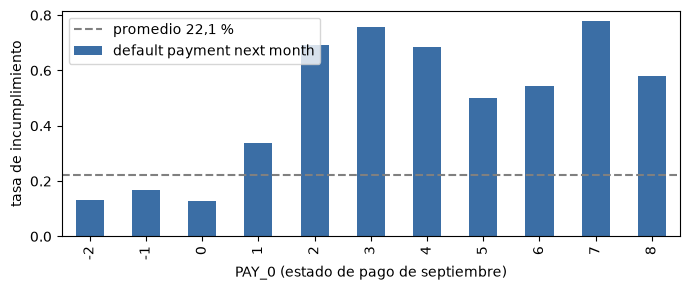

In [11]:
if df is None:
    print("Sin datos todavía: esta celda se ejecutará cuando coloques tu dataset en data/raw/.")
else:
    import matplotlib.pyplot as plt
    corr = df.drop(columns=ID_COL).corr()[TARGET].drop(TARGET)
    print("Correlación absoluta con el objetivo (las 6 más altas):")
    print(corr.abs().sort_values(ascending=False).head(6).round(3))
    rates = df.groupby("PAY_0")[TARGET].mean()
    ax = rates.plot(kind="bar", color="#3b6ea5", figsize=(7, 3))
    ax.axhline(df[TARGET].mean(), color="gray", ls="--", label="promedio 22,1 %")
    ax.set_ylabel("tasa de incumplimiento"); ax.set_xlabel("PAY_0 (estado de pago de septiembre)"); ax.legend()
    plt.tight_layout(); plt.show()

**Columnas y proceso.** `PAY_*`, `BILL_AMT*` y `PAY_AMT*` cubren de abril a septiembre, antes del mes que se predice. No se ve una fuga temporal evidente, siempre que esos datos estén disponibles al momento de decidir. `PAY_0` es la variable original más correlacionada con el objetivo (0,33), aunque no necesariamente la más importante en un modelo. Sus estados -2, -1 y 0 tienen entre 13 % y 17 % de incumplimiento y el código 2, 69,1 %; desde ahí las tasas no crecen de forma estricta (ver 3.3). Son asociaciones, no causas.

Se propone comparar el modelo con y sin `PAY_0` mediante validación dentro del entrenamiento; eso no sustituye la revisión de cuándo se conoce el dato. La prueba original ya se consultó en este EDA y se evaluó en el notebook de selección, así que no se usará para elegir variables, modelo, calibración ni umbral, ni se presentará como evaluación final independiente.


## 6. Referencias de negocio (exploratorias): regla simple y capacidad
**Pregunta:** una regla candidata marca a quien tiene `PAY_0 >= 2` en septiembre. No sabemos si es la política real del banco. ¿Qué recall, precision y penalización relativa tiene?
**Por qué importa:** un modelo complejo debe justificarse frente a una regla simple, comparando sobre las mismas observaciones de validación.
**Qué hace la celda:** evalúa la regla con todo el dataset y con la hipótesis 5 a 1 del grupo (no con costos reales del banco). La salida «costo esperado» es una penalización relativa, no dinero. También simula revisar el 5 %, 10 % o 20 % de los clientes, ordenados por `PAY_0` y `PAY_2`; son escenarios de capacidad supuestos, no capacidades medidas. El *lift* compara la tasa de incumplimiento del grupo revisado con la de todo el dataset.


In [12]:
if df is not None:
    from sklearn.metrics import precision_score, recall_score, roc_auc_score
    y = df[TARGET]
    regla = (df["PAY_0"] >= 2).astype(int)
    costo = (5 * ((y == 1) & (regla == 0)).sum() + ((y == 0) & (regla == 1)).sum()) / len(df)
    print("Regla: marcar si PAY_0 >= 2")
    print(f"  clientes marcados: {regla.mean():.1%} | recall: {recall_score(y, regla):.1%} | precision: {precision_score(y, regla):.1%}")
    print(f"  costo esperado por cliente (5 a 1): {costo:.3f}   [siempre 'paga': 1.106 | marcar a todos: 0.779]")
    print(f"  ROC AUC usando solo PAY_0: {roc_auc_score(y, df['PAY_0']):.4f}")
    print("\nSi el banco solo puede revisar a los clientes más riesgosos (ordenados por PAY_0 y PAY_2):")
    orden = df.assign(s=df["PAY_0"] + df["PAY_2"] * 0.01).sort_values("s", ascending=False)
    filas = []
    for k in (0.05, 0.10, 0.20):
        top = orden.head(int(k * len(df)))
        filas.append({"revisa el": f"{k:.0%}", "tasa de incumplimiento": round(top[TARGET].mean(), 3),
                      "lift": round(top[TARGET].mean() / y.mean(), 2), "% de incumplidores capturados": round(top[TARGET].sum() / y.sum(), 3)})
    display(pd.DataFrame(filas))

Regla: marcar si PAY_0 >= 2
  clientes marcados: 10.4% | recall: 32.8% | precision: 69.6%
  costo esperado por cliente (5 a 1): 0.775   [siempre 'paga': 1.106 | marcar a todos: 0.779]
  ROC AUC usando solo PAY_0: 0.6897

Si el banco solo puede revisar a los clientes más riesgosos (ordenados por PAY_0 y PAY_2):


,revisa el,tasa de incumplimiento,lift,% de incumplidores capturados
0,5%,0.723,3.27,0.164
1,10%,0.706,3.19,0.319
2,20%,0.536,2.43,0.485


**Lectura (dataset completo, exploratoria):**
- La regla marca al 10,4 % de los clientes, con precision de 69,6 % y recall de 32,8 %: detecta más o menos a 1 de cada 3 clientes que incumplen.
- Su penalización media (0,775) es casi igual a la de marcar a todos (0,779). El 0,57 del modelo viene del notebook 01 y es una referencia exploratoria pendiente de verificar; no se calculó sobre las mismas observaciones, así que no demuestra que el modelo supere a la regla ni un ahorro económico. La afirmación anterior de un «ahorro cercano al 27 %» se retira.
- Si se revisa primero al 5–10 % mejor ordenado, el lift es 3,2–3,3. Si se revisa el 20 %, el lift es 2,4 y se captura el 48,5 % de los clientes que incumplen. Son resultados descriptivos que dependen de cómo se ordenan los empates y de esta muestra; no prueban el efecto de contactar a los clientes.
- Con la matriz `[[0, 1], [5, 0]]`, el umbral teórico es `1/6 ≈ 0,167`, y solo vale para probabilidades calibradas y sin otros costos. `PAY_0 >= 2` es una regla sobre un código, no ese umbral. El umbral operativo se elegirá después, con validación dentro del entrenamiento.


## 7. Referencia de equidad (exploratoria)
**Pregunta:** `SEX`, `AGE` y `MARRIAGE` requieren revisión por grupos. ¿Cómo se comporta la regla simple en los grupos que se tabulan?
**Por qué importa:** las diferencias entre grupos pueden motivar una auditoría posterior, pero no bastan para demostrar discriminación ni su ausencia.
**Qué hace la celda:** para la regla `PAY_0 >= 2`, muestra la tasa de incumplimiento, el recall y el porcentaje marcado por sexo y por edad, con el dataset completo. No calcula errores por estado civil. Más adelante, la comparación entre la regla y el modelo debe usar las mismas observaciones.


In [13]:
if df is not None:
    from sklearn.metrics import recall_score
    regla = (df["PAY_0"] >= 2).astype(int)
    def por_grupo(g):
        return pd.Series({"clientes": len(g), "tasa real": g[TARGET].mean(), "recall": recall_score(g[TARGET], g["regla"]), "% marcados": g["regla"].mean()})
    base = df.assign(regla=regla)
    for nombre, clave in [("SEX (1 hombre, 2 mujer)", "SEX"), ("Edad", pd.cut(df["AGE"], [20, 30, 40, 50, 80]))]:
        print(f"--- {nombre} ---")
        display(base.groupby(clave).apply(por_grupo).round(3))

--- SEX (1 hombre, 2 mujer) ---


,clientes,tasa real,recall,% marcados
SEX,,,,
1,11888.0,0.242,0.327,0.115
2,18112.0,0.208,0.329,0.098


--- Edad ---


,clientes,tasa real,recall,% marcados
AGE,,,,
"(20, 30]",11013.0,0.224,0.350,0.114
"(30, 40]",10713.0,0.204,0.303,0.090
"(40, 50]",6005.0,0.233,0.330,0.104
"(50, 80]",2269.0,0.254,0.326,0.128


**Lectura:** el recall es parecido en hombres y mujeres (32,7 % y 32,9 %), aunque sus tasas de incumplimiento son 24,2 % y 20,8 %. Por edad, el recall varía entre 30 % y 35 %. Esto no demuestra equidad: faltan otras tasas de error, la precision y una medida de incertidumbre, y el análisis usa todo el dataset. Son asociaciones descriptivas, no explicaciones.

`MARRIAGE` tiene grupos de 54 y 323 clientes en la tabla de categorías, pero aquí no se calcularon sus errores. La auditoría posterior debe usar la agrupación definitiva, indicar cuántos clientes hay en cada grupo y comparar falsos positivos, precision y recall con su incertidumbre. No se inventan esos resultados.


## 8. Adelanto: ¿qué familia de modelos tiene sentido?
> **Es una exploración preliminar, no el torneo oficial.** La celda calcula la comparación, las predicciones fuera de muestra y la curva de aprendizaje solo con el 80 % de entrenamiento, con 5 pliegues estratificados y semilla 42. No usa `X_te` para esas métricas, pero las secciones anteriores ya exploraron el dataset completo y el notebook de selección ya evaluó la prueba original.

**Qué hace la celda:** compara cuatro configuraciones iniciales, revisa la calibración de HistGradientBoosting y mide el rendimiento con distintos tamaños de entrenamiento.
- **Calibración:** compara la probabilidad media predicha con la frecuencia real por quintiles. Es una evidencia agregada y preliminar; no garantiza calibración cerca del umbral ni en otros modelos.
- **Curva de aprendizaje:** muestra el ROC AUC medio con el 25 %, 50 %, 75 % y 100 % del entrenamiento de cada pliegue. Que la curva se aplane no demuestra que más datos sean inútiles; además, no se muestra su variación ni se repitió.


In [14]:
if df is not None:
    import warnings; warnings.filterwarnings("ignore")
    from lightgbm import LGBMClassifier
    from sklearn.compose import ColumnTransformer
    from sklearn.ensemble import HistGradientBoostingClassifier
    from sklearn.impute import SimpleImputer
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import brier_score_loss
    from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_val_score, learning_curve, train_test_split
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import OneHotEncoder, StandardScaler
    from xgboost import XGBClassifier

    d = df.drop(columns=ID_COL)
    cat = ["SEX", "EDUCATION", "MARRIAGE"]
    X, y = d.drop(columns=TARGET), d[TARGET]
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)   # X_te no se usa en este notebook
    num = [c for c in X.columns if c not in cat]
    def prep():
        return ColumnTransformer([("n", Pipeline([("i", SimpleImputer(strategy="median")), ("s", StandardScaler())]), num),
                                  ("c", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)])
    cv = StratifiedKFold(5, shuffle=True, random_state=42)

    modelos = {"Regresión logística": LogisticRegression(max_iter=2000, random_state=42),
               "HistGradientBoosting": HistGradientBoostingClassifier(random_state=42),
               "LightGBM": LGBMClassifier(random_state=42, verbose=-1),
               "XGBoost": XGBClassifier(random_state=42, eval_metric="logloss", n_jobs=1)}
    filas = []
    for nombre, m in modelos.items():
        s = cross_val_score(Pipeline([("p", prep()), ("m", m)]), X_tr, y_tr, cv=cv, scoring="roc_auc", n_jobs=-1)
        filas.append({"modelo": nombre, "ROC AUC (media)": round(s.mean(), 4), "desviación": round(s.std(), 4)})
    print("ROC AUC en validación cruzada (solo entrenamiento):")
    display(pd.DataFrame(filas).sort_values("ROC AUC (media)", ascending=False).reset_index(drop=True))

    hgb = Pipeline([("p", prep()), ("m", HistGradientBoostingClassifier(random_state=42))])
    oof = cross_val_predict(hgb, X_tr, y_tr, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
    print(f"\nCalibración (HistGradientBoosting). Brier = {brier_score_loss(y_tr, oof):.4f} (menor es mejor; sin modelo: {brier_score_loss(y_tr, [y_tr.mean()] * len(y_tr)):.4f})")
    display(pd.DataFrame({"probabilidad predicha": oof, "incumplimiento real": y_tr.values}).groupby(pd.qcut(oof, 5, duplicates="drop")).mean().round(3))

    tamanos, _, val = learning_curve(hgb, X_tr, y_tr, cv=cv, train_sizes=[0.25, 0.5, 0.75, 1.0], scoring="roc_auc", n_jobs=-1)
    print("\nCurva de aprendizaje (ROC AUC según filas de entrenamiento):")
    display(pd.DataFrame({"filas de entrenamiento": tamanos, "ROC AUC": val.mean(axis=1).round(4)}))

ROC AUC en validación cruzada (solo entrenamiento):


,modelo,ROC AUC (media),desviación
0,LightGBM,0.7813,0.0057
1,HistGradientBoosting,0.7806,0.0063
2,XGBoost,0.7668,0.0074
3,Regresión logística,0.7272,0.0115



Calibración (HistGradientBoosting). Brier = 0.1339 (menor es mejor; sin modelo: 0.1723)


,probabilidad predicha,incumplimiento real
"(0.009899999999999999, 0.0784]",0.056,0.057
"(0.0784, 0.122]",0.100,0.101
"(0.122, 0.175]",0.147,0.155
"(0.175, 0.327]",0.235,0.226
"(0.327, 0.918]",0.568,0.567



Curva de aprendizaje (ROC AUC según filas de entrenamiento):


,filas de entrenamiento,ROC AUC
0,4800,0.7638
1,9600,0.7702
2,14400,0.7797
3,19200,0.7806


**Lectura:**
- **Promedios muy cercanos:** LightGBM 0,7813 e HistGradientBoosting 0,7806 (como referencia histórica, Gradient Boosting dio 0,7815). XGBoost con valores iniciales queda en 0,7668 y la regresión logística en 0,7272. La diferencia entre los dos primeros es pequeña frente a la variación entre pliegues (≈ 0,006), aunque eso no prueba un empate. Para elegir hace falta comparar configuraciones ajustadas y diferencias pareadas, dentro del entrenamiento.
- **Calibración de HistGradientBoosting:** en el quintil superior, la probabilidad predicha media es 0,568 y la observada 0,567; el Brier es 0,1339, mejor que el de una referencia constante (0,1723). El Brier no mide solo calibración y cinco quintiles pueden esconder fallos locales. No garantiza calibración cerca de `1/6 ≈ 0,167` ni en el Gradient Boosting optimizado; hay que comprobarlo en el modelo concreto.
- **Ganancia pequeña con más datos:** pasar de 14.400 a 19.200 filas sube el AUC solo 0,0009. Sin repeticiones ni tamaños mayores, no se puede concluir que más datos ayuden poco ni que mejores variables garanticen mejoras.
- **Candidatos para el torneo:** gradient boosting y, como contraste explicable, regresión logística. No hay ganador definitivo ni utilidad económica demostrada. SHAP puede describir cuánto contribuyó cada variable a una predicción, pero no explica causas ni el efecto de intervenir.


## 9. Tabla de decisiones (entregable del EDA)

Las cifras son resultados guardados. Las decisiones sobre modelos son hipótesis que se validan dentro del entrenamiento, sin usar la prueba para elegir. Esta tabla es la foto del EDA; lo que se hizo después está en los notebooks 03 y 04.

| # | Hallazgo (con cifra) | Decisión | Motivo |
|---|---|---|---|
| 1 | 30.000 ID distintos, uno por fila | Mantener la partición 80/20, estratificada, semilla 42, y excluir el ID | Ningún ID queda en dos partes; no cambia que la prueba ya se vio |
| 2 | 22,12 % incumple; «siempre paga»: exactitud 77,88 %, recall 0 % | Usar ROC AUC, recall y AUC-PR; medir también la penalización relativa y la carga de revisión | La exactitud sola no mide la detección ni la hipótesis 5 a 1 |
| 3 | EDUCATION 0, 5 y 6: 345 clientes (1,15 %); MARRIAGE 0: 54 | Agrupar en «otros» (4 y 3) antes de codificar, con la misma regla en entrenamiento e inferencia | Es una convención, no un significado demostrado; hay que integrarla al pipeline |
| 4 | PAY_0: estados -2, -1 y 0 con 13–17 %; código 2, 69,1 %; código 5, 50,0 % | Dejar los códigos como números por ahora y comparar otras codificaciones con validación | Mezclan estados y meses de atraso; la relación no es causal ni siempre creciente; hay que documentar los códigos |
| 5 | 1.930 clientes (6,43 %) con BILL_AMT negativo; PAY_AMT2: p99 76.651, máximo 1.684.259 | Conservar los negativos plausibles; usar log1p solo donde se pueda; comparar Yeo-Johnson dentro del pipeline | log y log1p no sirven con todos los negativos; cualquier transformación se aprende solo con entrenamiento |
| 6 | Mujeres: tasa 20,8 %, recall de la regla 32,9 %; hombres: 24,2 % y 32,7 % | Probar con y sin SEX y revisar errores por sexo, edad y estado civil | Un recall parecido no demuestra equidad; faltan otras métricas e incertidumbre |
| 7 | PAY_0: correlación 0,33 con el objetivo | Comparar el modelo con y sin PAY_0 y confirmar que se conoce al decidir | Mide cuánto depende el modelo de ella; no prueba causalidad ni ausencia de fuga |
| 8 | 35 filas idénticas sin ID; 3.931 clientes sobre su límite | Conservar las filas y documentar que son plausibles | Los ID son distintos y las coincidencias no prueban errores |
| 9 | n_atraso: correlación 0,40 frente a 0,33 de PAY_0; tasas de 11,7 % a 70,3 % | Conservarla como candidata y medir con validación si mejora el modelo | Es una asociación; no demuestra que aporte algo nuevo |
| 10 | Facturas: correlación media 0,89; ratio_pago −0,01 y tendencia −0,03 con el objetivo | Comparar resúmenes o regularización, y las candidatas; definir cómo tratar vacíos y extremos del ratio | Una correlación lineal baja no descarta una relación más compleja ni obliga a eliminar variables |
| 11 | Regla: penalización 0,775; marcar a todos: 0,779; referencia exploratoria del modelo: 0,57 | Comparar las alternativas con las mismas observaciones de validación y la misma matriz | No demuestra un ahorro del 27 % ni impacto económico; el 0,57 está pendiente de verificar |
| 12 | LightGBM 0,7813; HistGradientBoosting 0,7806; XGBoost 0,7668; logística 0,7272 | Mantener boosting y logística como candidatos, sin ganador | Son promedios exploratorios; falta comparar con diferencias pareadas y configuraciones ajustadas |
| 13 | HistGradientBoosting: quintil superior predicho 0,568 y observado 0,567 | Revisar la calibración del modelo concreto cerca del umbral y elegir el umbral solo con validación | La evidencia es preliminar y agregada; no garantiza calibración cerca de 1/6 ≈ 0,167 |
| 14 | De 14.400 a 19.200 filas: el AUC sube 0,0009 | Dejar abiertas las dos hipótesis: más datos y mejores variables | Sin variación ni repeticiones no se puede decir que ya se saturó ni que habrá mejoras |

**Seguimiento posterior.** Las decisiones 1, 3 y 8 ya son código con pruebas en el notebook 03 (limpieza y partición). Las decisiones 6, 7 y 9 se midieron en el notebook 04 (ver `reports/04_features.md`): sin `PAY_0` el AUC baja unos 0,03, sin `SEX` baja unos 0,001, y `n_atraso` no mejora ningún modelo. Siguen abiertas la 4 (codificación de `PAY_*`), la 5 (transformación de montos) y la 10 (resumen de facturas).


## Entregable de esta etapa

- [x] Las salidas guardadas son las de la ejecución anterior de este notebook; la revisión H1 y esta edición solo cambiaron textos.
- [x] La tabla de decisiones tiene al menos 5 filas con cifra y motivo (tiene 14).
- [x] `reports/01_eda.md` está actualizado.
- [x] La unidad de análisis está declarada por escrito.

**Siguiente:** las decisiones ya se llevaron a código en `03_preprocesamiento.ipynb` (limpieza y partición) y se midieron en `04_features.ipynb` (variables). Quedan para las etapas siguientes la transformación de montos, la codificación de `PAY_*` y la auditoría de equidad.
